# Thống kê DCSS, IM-DCSS và ADA-IM-DCSS

**Mở file này và chọn Run all. Không cần GPU, PyTorch, dữ liệu ảnh/văn bản hoặc
notebook huấn luyện.** Trên Colab, chọn **Python 3 → CPU**.

Bản kết quả đã kiểm tra ngày **15/11/2026 được nhúng ngay trong file**: năm bộ
mới, 250 bản kết quả, 25.000 bản ghi epoch; thêm 50 kết quả Fashion-MNIST 70k làm
đối chiếu lịch sử. Có thể chuyển sang đọc thư mục Drive hoặc thư mục máy ở ô 1.
Chế độ mặc định không cần gắn Drive. Kết quả gốc luôn chỉ được đọc.

Notebook cung cấp: tiến độ → ARI/NMI/ACC → chỉ số nội tại Nemotron → so sánh ghép
cặp → suy biến/số cụm → độ ổn định → đường học → dữ liệu từng seed → xuất CSV/JSON,
biểu đồ và HTML. Bản đã thực thi có thể xem ngay các bảng và hình khi mở.

**Phạm vi:** tính lại thống kê từ điểm và lịch sử đã lưu; không tải model hoặc tính
lại mọi điểm từ dự đoán. Độ ổn định phân hoạch lấy từ tệp thống kê đã lưu.
Bốn bộ mới có nhãn dùng đánh giá transductive toàn tập, không phải tập kiểm thử
độc lập. Nemotron không có nhãn cụm chuẩn; không báo ARI/NMI/ACC theo nhãn đúng.

## 1. Chọn nguồn kết quả và thư mục xuất
Giữ nguyên mặc định để chạy ngay. Chỉ cần đổi nguồn khi muốn đọc kết quả khác.

In [1]:
from pathlib import Path
import sys, importlib.util, subprocess
SOURCE_MODE = "snapshot"       # "snapshot", "drive" hoặc "local"
DATA_ROOT_OVERRIDE = None      # Dùng với local; thư mục chứa har_..., emnist_..., ...
FASHION_ROOT_OVERRIDE = None   # None = DCSS_FashionMNIST_Full bên cạnh thư mục mới
OUTPUT_DIR = Path.cwd() / "DCSS_MultiDataset_Statistics"

requirements = {"numpy":"numpy", "pandas":"pandas", "scipy":"scipy", "matplotlib":"matplotlib"}
missing = [pkg for module,pkg in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
get_ipython().run_line_magic("matplotlib","inline")
assert SOURCE_MODE in {"snapshot","drive","local"}
print("Chế độ:",SOURCE_MODE)
print("Thư mục xuất:",OUTPUT_DIR)

Chế độ: snapshot
Thư mục xuất: F:\ThacSi\Data Mining\final\DCSS_MultiDataset_Statistics


## 2. Nạp bộ phân tích và kết quả đã kiểm tra
Hai ô mã thu gọn dưới đây giúp notebook hoạt động độc lập. Không có lệnh huấn luyện.

In [2]:
import types, sys
ANALYSIS_SOURCE = '"""CPU-only result reader. Never imports a training module or opens checkpoints."""\nfrom __future__ import annotations\nimport base64\nimport gzip\nimport hashlib\nimport itertools\nimport json\nimport math\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nfrom scipy import stats\nimport matplotlib.pyplot as plt\n\nDATASETS = ("emnist", "har", "pendigits", "waveform", "personas")\nFASHION = "fashion_mnist_70k_historical"\nMETHODS = ("ae_kmeans", "dcss_paper", "dcss_rms", "im_rms", "ada_im")\nMETHOD_NAMES = {"ae_kmeans":"AE + KMeans", "dcss_paper":"DCSS", "dcss_rms":"DCSS-RMS", "im_rms":"IM-DCSS", "ada_im":"ADA-IM-DCSS"}\nDATA_NAMES = {FASHION:"Fashion-MNIST 70k (đối chiếu cũ)", "emnist":"EMNIST Balanced", "har":"HAR",\n              "pendigits":"Pendigits", "waveform":"Waveform V1", "personas":"Nemotron 100k"}\nMETRICS = ("ARI", "NMI", "ACC", "silhouette_common", "DB_common", "CH_common")\nMETRIC_NAMES = {"silhouette_common":"Silhouette chung", "DB_common":"Davies–Bouldin", "CH_common":"Calinski–Harabasz",\n                "ARI":"ARI", "NMI":"NMI", "ACC":"ACC"}\nCOLORS = ["#64748b", "#c98735", "#8c6bb1", "#167d9a", "#c13e63"]\nHISTORY_FIELDS = ("epoch", "loss", "reconstruction", "soft_silhouette", "conditional_entropy", "balance_kl",\n                  "active_clusters", "seconds", "seen", "peak_gpu_gb")\n\n\ndef sha(path):\n    return hashlib.sha256(Path(path).read_bytes()).hexdigest()\n\n\ndef read(path):\n    return json.loads(Path(path).read_text(encoding="utf-8"))\n\n\ndef unpack_snapshot(encoded, expected_sha):\n    packed = base64.b64decode(encoded, validate=True)\n    if hashlib.sha256(packed).hexdigest() != expected_sha:\n        raise ValueError("Snapshot checksum mismatch")\n    return json.loads(gzip.decompress(packed))\n\n\ndef read_campaign(root, fashion_root=None):\n    """Read data files only. Retain each raw-result checksum in the snapshot."""\n    root = Path(root).resolve()\n    payload = dict(schema=1, source=str(root), snapshot_date=None, records=[], histories=[], datasets={}, stability=[])\n    for dataset in DATASETS:\n        matches = list(root.glob(dataset+"_*/manifest.json"))\n        if len(matches) != 1:\n            raise ValueError(f"{dataset}: cần đúng một manifest; tìm thấy {len(matches)}")\n        manifest_path = matches[0]\n        directory = manifest_path.parent\n        manifest = read(manifest_path)\n        cfg, meta = manifest["config"], manifest["data"]\n        payload["datasets"][dataset] = dict(n=meta["n"], k=cfg["n_clusters"], seeds=cfg["seeds"],\n            pretrain_epochs=cfg["pretrain_epochs"], cluster_epochs=cfg["cluster_epochs"], identity=manifest["identity"],\n            manifest_sha256=sha(manifest_path), raw_folder=directory.name, labeled=cfg["labeled"],\n            stored_completion=read(directory/"completeness.json") if (directory/"completeness.json").exists() else None,\n            embedding=meta.get("embedding"), configuration=cfg)\n        for path in sorted(directory.glob("seed_*/*/result.json")):\n            raw = read(path)\n            record = {k:v for k,v in raw.items() if k not in {"execution_trace","evaluation_environment"}}\n            record["dataset"] = dataset\n            record["raw_result_sha256"] = sha(path)\n            trace = raw.get("execution_trace", [])\n            record["hardware"] = sorted({t["environment"].get("gpu") or t["environment"]["device"] for t in trace})\n            record["environment_signatures"] = sorted({hashlib.sha256(json.dumps(t["environment"], sort_keys=True).encode()).hexdigest() for t in trace})\n            payload["records"].append(record)\n        for path in sorted(directory.glob("seed_*/*/history.json")):\n            history = read(path)\n            payload["histories"].append(dict(dataset=dataset, seed=int(path.parent.parent.name.split("_")[1]),\n                phase=path.parent.name, raw_history_sha256=sha(path),\n                rows=[{k:r[k] for k in HISTORY_FIELDS if k in r} for r in history]))\n        if (directory/"partition_stability.json").exists():\n            payload["stability"] += [dict(dataset=dataset, **row) for row in read(directory/"partition_stability.json")]\n    if fashion_root is not None:\n        old = list(Path(fashion_root).glob("paper70k_*/manifest.json"))\n        if len(old) != 1:\n            raise ValueError("Fashion-MNIST: cần đúng một hồ sơ paper70k")\n        directory = old[0].parent\n        manifest = read(old[0])\n        payload["datasets"][FASHION] = dict(n=70000, k=10, seeds=manifest["config"]["seeds"],\n            labeled=True, historical=True, manifest_sha256=sha(old[0]), raw_folder=directory.name)\n        paths = list(directory.glob("seed_*/*/result.json")) + list(directory.glob("seed_*/ae_kmeans_evaluation.json"))\n        for path in sorted(paths):\n            raw = read(path)\n            method = raw.get("method", "ae_kmeans")\n            payload["records"].append(dict(dataset=FASHION, method=method, seed=raw["seed"], n=70000,\n                status="complete", historical=True, mixed_environment=True, raw_result_sha256=sha(path),\n                **{m:raw[m] for m in ("ARI","NMI","ACC")}))\n    return payload\n\n\ndef validate_payload(payload):\n    records = payload["records"]\n    keys = [(r["dataset"],r["seed"],r["method"]) for r in records]\n    if len(set(keys)) != len(keys):\n        raise ValueError("Trùng dataset/seed/phương pháp; không được trộn lượt chạy")\n    for r in records:\n        d = r["dataset"]\n        meta = payload["datasets"][d]\n        if r["method"] not in METHODS or r["seed"] not in meta["seeds"] or r["n"] != meta["n"] or r["status"] != "complete":\n            raise ValueError("Kết quả không khớp manifest")\n        if d == FASHION:\n            continue\n        if r["identity"] != meta["identity"]+f":{r[\'seed\']}:{r[\'method\']}":\n            raise ValueError("Sai danh tính kết quả")\n        if len(r["cluster_counts"]) != meta["k"] or sum(r["cluster_counts"]) != r["n"]:\n            raise ValueError("Sai số mẫu/cụm trong dự đoán đã lưu")\n        if r["hard_active_clusters"] != sum(x>0 for x in r["cluster_counts"]):\n            raise ValueError("Sai số cụm hoạt động")\n        if not meta["labeled"] and any(r.get(m) is not None for m in ("ARI","NMI","ACC")):\n            raise ValueError("Không được tạo nhãn đúng giả cho Nemotron")\n        for m in METRICS:\n            if r.get(m) is not None and not math.isfinite(r[m]):\n                raise ValueError("Chỉ số không hữu hạn; dùng null khi không xác định")\n    history_index = {(h["dataset"],h["seed"],h["phase"]):h for h in payload["histories"]}\n    if len(history_index) != len(payload["histories"]):\n        raise ValueError("Trùng lịch sử huấn luyện")\n    for r in records:\n        d = r["dataset"]\n        if d == FASHION:\n            continue\n        meta = payload["datasets"][d]\n        for phase,total in [("pretrain",meta["pretrain_epochs"])] + ([] if r["method"]=="ae_kmeans" else [(r["method"],meta["cluster_epochs"])]):\n            history = history_index.get((d,r["seed"],phase),{}).get("rows",[])\n            if [row["epoch"] for row in history] != list(range(1,total+1)):\n                raise ValueError(f"{d}/{r[\'seed\']}/{phase}: kết quả cuối thiếu lịch sử epoch")\n            if not all(row["seen"]==meta["n"] and math.isfinite(row["loss"]) for row in history):\n                raise ValueError("Lịch sử có loss lỗi hoặc sai số mẫu")\n    for d in DATASETS:\n        rows = [r for r in records if r["dataset"]==d]\n        if len({r["common_sample_sha256"] for r in rows})>1:\n            raise ValueError("Các phương pháp dùng mẫu đánh giá nội tại khác nhau")\n    return dict(records=len(records), new_results=sum(r["dataset"]!=FASHION for r in records),\n                history_phases=len(payload["histories"]), epoch_rows=sum(len(h["rows"]) for h in payload["histories"]),\n                verification="JSON và lịch sử; không tính lại dự đoán từ model/checkpoint")\n\n\ndef result_frame(payload):\n    frame = pd.DataFrame(payload["records"])\n    for m in METRICS:\n        if m not in frame:\n            frame[m] = np.nan\n        frame[m] = pd.to_numeric(frame[m],errors="raise")\n    return frame\n\n\ndef make_tables(payload):\n    validate_payload(payload)\n    frame = result_frame(payload)\n    progress, summaries, health = [], [], []\n    for d,meta in payload["datasets"].items():\n        group = frame[frame.dataset==d]\n        expected = {(s,m) for s in meta["seeds"] for m in METHODS}\n        actual = set(zip(group.seed,group.method))\n        signatures = {v for r in payload["records"] if r["dataset"]==d for v in r.get("environment_signatures",[])}\n        mixed = len(signatures)>1 or bool(group.mixed_environment.fillna(False).any())\n        progress.append(dict(dataset=d,samples=meta["n"],K=meta["k"],completed=len(actual),expected=len(expected),\n            complete=actual==expected,seeds=len(meta["seeds"]),mixed_environment=mixed,historical=d==FASHION))\n        for method in METHODS:\n            g = group[group.method==method]\n            for metric in METRICS:\n                if d==FASHION and metric not in ("ARI","NMI","ACC") or d=="personas" and metric in ("ARI","NMI","ACC"):\n                    continue\n                v = g[metric].dropna()\n                summaries.append(dict(dataset=d,method=method,metric=metric,completed=len(g),expected=len(meta["seeds"]),\n                    valid=len(v),undefined=len(g)-len(v),mean=float(v.mean()) if len(v) else np.nan,\n                    sample_sd=float(v.std(ddof=1)) if len(v)>1 else np.nan))\n            if d!=FASHION:\n                health.append(dict(dataset=d,method=method,completed=len(g),K=meta["k"],\n                    flagged_collapsed=int(g.collapsed.fillna(False).sum()) if method!="ae_kmeans" and len(g) else np.nan,\n                    single_cluster_runs=int((g.hard_active_clusters==1).sum()),\n                    active_min=float(g.hard_active_clusters.min()) if len(g) else np.nan,\n                    active_mean=float(g.hard_active_clusters.mean()) if len(g) else np.nan,\n                    active_max=float(g.hard_active_clusters.max()) if len(g) else np.nan,\n                    largest_cluster_max=float(g.hard_largest_cluster_fraction.max()) if len(g) else np.nan,\n                    undefined_internal=int(g.silhouette_common.isna().sum())))\n    return frame,pd.DataFrame(progress),pd.DataFrame(summaries),pd.DataFrame(health)\n\n\ndef paired(d):\n    a = np.asarray(d,dtype=float)\n    n = len(a)\n    out = dict(n=n,mean_delta=float(a.mean()) if n else np.nan,wins=int((a>0).sum()),losses=int((a<0).sum()),ties=int((a==0).sum()))\n    if n<2:\n        return dict(**out,ci95_low=np.nan,ci95_high=np.nan,p_raw=np.nan)\n    margin = float(stats.t.ppf(.975,n-1)*a.std(ddof=1)/math.sqrt(n))\n    signs = np.asarray(list(itertools.product([-1.,1.],repeat=n))) if n<=16 else None\n    return dict(**out,ci95_low=out["mean_delta"]-margin,ci95_high=out["mean_delta"]+margin,\n                p_raw=float(np.mean(np.abs((signs*a).mean(1))>=abs(a.mean())-1e-15)) if signs is not None else np.nan)\n\n\ndef holm(values):\n    p = np.asarray(values,dtype=float)\n    order = np.argsort(p,kind="stable")\n    out = np.empty_like(p)\n    out[order] = np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]))\n    return out\n\n\ndef comparisons(frame,payload):\n    rows = []\n    for d in DATASETS:\n        for baseline in METHODS[:-1]:\n            metrics = METRICS[3:] if d=="personas" else METRICS\n            for metric in metrics:\n                a = frame[(frame.dataset==d)&(frame.method=="ada_im")].set_index("seed")[metric].dropna()\n                b = frame[(frame.dataset==d)&(frame.method==baseline)].set_index("seed")[metric].dropna()\n                common = a.index.intersection(b.index).sort_values()\n                rows.append(dict(dataset=d,comparison="ada_im - "+baseline,metric=metric,\n                    primary=baseline=="im_rms" and metric==("silhouette_common" if d=="personas" else "ARI"),\n                    complete=set(common)==set(payload["datasets"][d]["seeds"]),**paired(a.loc[common]-b.loc[common])))\n    all_pairs = pd.DataFrame(rows)\n    primary = all_pairs[all_pairs.primary].copy()\n    if set(primary.dataset)!=set(DATASETS) or len(primary)!=5:\n        raise ValueError("Họ kiểm định chính phải có đúng 5 bộ")\n    values = [r.p_raw if r.complete and pd.notna(r.p_raw) else 1. for r in primary.itertuples()]\n    primary["p_holm_family5"] = [p if done else np.nan for p,done in zip(holm(values),primary.complete)]\n    return all_pairs,primary\n\n\ndef display_summary(summary,dataset,metrics):\n    rows = []\n    for method in METHODS:\n        row = {"Phương pháp":METHOD_NAMES[method]}\n        for metric in metrics:\n            g = summary[(summary.dataset==dataset)&(summary.method==method)&(summary.metric==metric)]\n            if g.empty:\n                continue\n            r = g.iloc[0]\n            factor = 100 if metric in ("ARI","NMI","ACC") else 1\n            value = "—" if pd.isna(r["mean"]) else f"{factor*r[\'mean\']:.3f} ± {factor*r[\'sample_sd\']:.3f}"\n            row[METRIC_NAMES[metric]+(" ×100" if factor==100 else "")] = value\n            row[metric+" (hợp lệ/đã xong)"] = f"{int(r.valid)}/{int(r.completed)}"\n        rows.append(row)\n    return pd.DataFrame(rows)\n\n\ndef save_show(fig,path):\n    path = Path(path)\n    path.parent.mkdir(parents=True,exist_ok=True)\n    fig.savefig(path,dpi=160,bbox_inches="tight")\n    plt.show()\n    plt.close(fig)\n\n\ndef plot_label_scores(frame,summary,out):\n    datasets = [d for d in (FASHION,*DATASETS) if d!="personas" and d in set(summary.dataset)]\n    fig,axes = plt.subplots(len(datasets),3,figsize=(16,3.5*len(datasets)),squeeze=False,layout="constrained")\n    for row,d in enumerate(datasets):\n        for col,metric in enumerate(("ARI","NMI","ACC")):\n            ax = axes[row,col]\n            for i,m in enumerate(METHODS):\n                s = summary[(summary.dataset==d)&(summary.method==m)&(summary.metric==metric)].iloc[0]\n                if pd.notna(s["mean"]):\n                    ax.bar(i,100*s["mean"],yerr=100*s.sample_sd if pd.notna(s.sample_sd) else 0,color=COLORS[i],capsize=3,alpha=.8)\n                g = frame[(frame.dataset==d)&(frame.method==m)].sort_values("seed")\n                ax.scatter(i+np.linspace(-.12,.12,len(g)),100*g[metric],s=13,color="#1f2937",alpha=.55,zorder=3)\n            ax.set_xticks(range(5),[METHOD_NAMES[m] for m in METHODS],rotation=25,ha="right",fontsize=8)\n            ax.set_title(DATA_NAMES[d]+" · "+metric)\n            ax.set_ylabel(metric+" ×100 · TB ± SD; chấm = seed")\n            ax.grid(axis="y",alpha=.2)\n    save_show(fig,Path(out)/"01_label_scores_all_seeds.png")\n\n\ndef plot_personas(frame,summary,out):\n    fig,axes = plt.subplots(1,3,figsize=(17,4.8),layout="constrained")\n    for ax,metric in zip(axes,METRICS[3:]):\n        for i,m in enumerate(METHODS):\n            s=summary[(summary.dataset=="personas")&(summary.method==m)&(summary.metric==metric)].iloc[0]\n            if pd.notna(s["mean"]):\n                ax.bar(i,s["mean"],yerr=s.sample_sd if pd.notna(s.sample_sd) else 0,color=COLORS[i],capsize=3)\n                ax.annotate(f"n={int(s.valid)}/{int(s.completed)}",(i,s["mean"]),xytext=(0,12),textcoords="offset points",ha="center",fontsize=8)\n        ax.set_xticks(range(5),[METHOD_NAMES[m] for m in METHODS],rotation=30,ha="right")\n        ax.set_title(METRIC_NAMES[metric]+(" ↓" if metric=="DB_common" else " ↑"))\n        ax.grid(axis="y",alpha=.2)\n    fig.suptitle("Nemotron · cùng đặc trưng/mẫu đánh giá; xem số cụm và suy biến trước khi diễn giải")\n    save_show(fig,Path(out)/"02_personas_internal_metrics.png")\n\n\ndef plot_primary(primary,out):\n    fig,axes=plt.subplots(1,2,figsize=(14,4.5),layout="constrained",gridspec_kw={"width_ratios":[2,1]})\n    for ax,subset,factor in [(axes[0],primary[primary.dataset!="personas"],100),(axes[1],primary[primary.dataset=="personas"],1)]:\n        for i,r in enumerate(subset.itertuples()):\n            if pd.isna(r.ci95_low):\n                continue\n            ax.errorbar(r.mean_delta*factor,i,xerr=[[factor*(r.mean_delta-r.ci95_low)],[factor*(r.ci95_high-r.mean_delta)]],\n                        fmt="o",color="#c13e63",capsize=5)\n            p = f"{r.p_holm_family5:.4f}" if pd.notna(r.p_holm_family5) else "chưa đủ"\n            ax.annotate("p Holm="+p,(r.mean_delta*factor,i),xytext=(0,12),textcoords="offset points",ha="center",fontsize=9)\n        ax.set_yticks(range(len(subset)),[DATA_NAMES[d] for d in subset.dataset])\n        ax.axvline(0,color="#475569",linestyle="--")\n        ax.margins(y=.3)\n        ax.grid(axis="x",alpha=.2)\n        ax.set_xlabel("Chênh lệch ARI ×100" if factor==100 else "Chênh lệch silhouette")\n    fig.suptitle("ADA-IM − IM: trung bình và CI 95% chưa hiệu chỉnh; p Holm theo họ 5 phép thử")\n    save_show(fig,Path(out)/"03_primary_paired_comparisons.png")\n\n\ndef plot_health(health,out):\n    fig,axes=plt.subplots(1,2,figsize=(15,5),layout="constrained")\n    for ax,column,title in [(axes[0],"flagged_collapsed","Tỷ lệ lượt bị đánh dấu suy biến"),(axes[1],"active_mean","Tỷ lệ số cụm hoạt động trung bình / K")]:\n        matrix=np.full((5,5),np.nan)\n        labels={}\n        for i,d in enumerate(DATASETS):\n            for j,m in enumerate(METHODS):\n                r=health[(health.dataset==d)&(health.method==m)].iloc[0]\n                val=r[column]\n                if pd.notna(val) and r.completed:\n                    matrix[i,j]=val/(r.completed if column=="flagged_collapsed" else r.K)\n                    labels[i,j]=f"{int(val)}/{int(r.completed)}" if column=="flagged_collapsed" else f"{val:.1f}/{int(r.K)}"\n                else:\n                    labels[i,j]="—"\n        palette=plt.get_cmap("YlOrRd" if column=="flagged_collapsed" else "YlGnBu").copy()\n        palette.set_bad("#e5e7eb")\n        im=ax.imshow(matrix,vmin=0,vmax=1,cmap=palette,aspect="auto")\n        for (i,j),s in labels.items():\n            ax.text(j,i,s,ha="center",va="center",color="white" if np.isfinite(matrix[i,j]) and matrix[i,j]>.6 else "#111827",fontsize=9)\n        ax.set_xticks(range(5),[METHOD_NAMES[m] for m in METHODS],rotation=25,ha="right")\n        ax.set_yticks(range(5),[DATA_NAMES[d] for d in DATASETS])\n        ax.set_title(title)\n        fig.colorbar(im,ax=ax,shrink=.7)\n    save_show(fig,Path(out)/"04_cluster_health.png")\n\n\ndef plot_stability(payload,out):\n    frame=pd.DataFrame(payload["stability"])\n    fig,axes=plt.subplots(2,3,figsize=(16,8),layout="constrained")\n    for ax,d in zip(axes.ravel(),DATASETS):\n        for i,m in enumerate(METHODS):\n            g=frame[(frame.dataset==d)&(frame.method==m)]\n            if not g.empty and pd.notna(g.iloc[0].partition_ARI_mean):\n                r=g.iloc[0]\n                ax.bar(i,r.partition_ARI_mean,color=COLORS[i],alpha=.85)\n        ax.set_xticks(range(5),[METHOD_NAMES[m] for m in METHODS],rotation=25,ha="right",fontsize=8)\n        ax.set_title(DATA_NAMES[d])\n        ax.set_ylabel("ARI trung bình giữa phân hoạch của các seed")\n        ax.grid(axis="y",alpha=.2)\n    axes.ravel()[-1].axis("off")\n    fig.suptitle("Độ ổn định: 45 cặp phụ thuộc nhau; không phải ARI theo nhãn đúng")\n    save_show(fig,Path(out)/"05_partition_stability.png")\n\n\ndef history_frame(payload):\n    return pd.DataFrame([dict(dataset=h["dataset"],seed=h["seed"],phase=h["phase"],**r) for h in payload["histories"] for r in h["rows"]])\n\n\ndef plot_histories(payload,out):\n    frame=history_frame(payload)\n    fig,axes=plt.subplots(2,5,figsize=(22,8),layout="constrained")\n    for col,d in enumerate(DATASETS):\n        for row,metric in enumerate(("reconstruction","soft_silhouette")):\n            ax=axes[row,col]\n            for i,m in enumerate(METHODS[1:],start=1):\n                g=frame[(frame.dataset==d)&(frame.phase==m)].groupby("epoch")[metric].agg(["mean","std"])\n                if len(g):\n                    ax.plot(g.index,g["mean"],label=METHOD_NAMES[m],color=COLORS[i],linewidth=1.5)\n                    ax.fill_between(g.index,g["mean"]-g["std"].fillna(0),g["mean"]+g["std"].fillna(0),color=COLORS[i],alpha=.12)\n            ax.set_title(DATA_NAMES[d])\n            ax.set_xlabel("Epoch")\n            ax.set_ylabel("MSE tái tạo" if row==0 else "Silhouette mềm mini-batch")\n            ax.grid(alpha=.2)\n    handles,labels=axes[0,0].get_legend_handles_labels()\n    fig.legend(handles,labels,loc="outside lower center",ncol=4)\n    fig.suptitle("Quá trình tinh chỉnh: trung bình ± SD qua các seed; không chọn epoch theo nhãn")\n    save_show(fig,Path(out)/"06_training_histories.png")\n\n\ndef cluster_detail(frame,dataset="personas",method="ada_im",seed=0):\n    if dataset==FASHION:\n        raise ValueError("Snapshot Fashion chỉ dùng đối chiếu chỉ số")\n    g=frame[(frame.dataset==dataset)&(frame.method==method)&(frame.seed==seed)]\n    if len(g)!=1:\n        raise ValueError("Không có đúng một kết quả đã chọn")\n    counts=g.iloc[0].cluster_counts\n    return pd.DataFrame({"Cụm":range(len(counts)),"Số mẫu":counts,"Tỷ lệ":np.array(counts)/sum(counts)})\n\n\ndef export_tables(out,payload,frame,progress,summary,health,all_pairs,primary):\n    out=Path(out)\n    out.mkdir(parents=True,exist_ok=True)\n    source=payload.get("source")\n    if source and Path(source).is_dir() and (out.resolve()==Path(source).resolve() or out.resolve().is_relative_to(Path(source).resolve())):\n        raise ValueError("Thư mục xuất phải nằm ngoài thư mục kết quả gốc")\n    tables={"per_seed":frame.drop(columns=["environment_signatures","cluster_counts"],errors="ignore"),\n        "progress":progress,"summary":summary,"cluster_health":health,"all_paired_comparisons":all_pairs,\n        "primary_comparisons_holm":primary,"partition_stability":pd.DataFrame(payload["stability"]),\n        "training_history":history_frame(payload)}\n    for name,table in tables.items():\n        table.to_csv(out/(name+".csv"),index=False,encoding="utf-8-sig")\n        (out/(name+".json")).write_text(table.to_json(orient="records",force_ascii=False,indent=2),encoding="utf-8")\n    report=dict(source=source,snapshot_date=payload.get("snapshot_date"),validation=validate_payload(payload),\n                units="raw fractions in CSV/JSON; SD uses ddof=1",\n                limitation="Reads stored scores/histories; does not recompute all metrics from predictions.npz",\n                stability_source="stored partition_stability.json; descriptive dependent seed pairs")\n    (out/"analysis_provenance.json").write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding="utf-8")\n    return tables\n\n\ndef export_html_zip(out,tables,primary):\n    import zipfile\n    out=Path(out)\n    html=[\'<!doctype html><html lang="vi"><meta charset="utf-8"><title>Thống kê DCSS nhiều bộ dữ liệu</title>\',\n          \'<style>body{font:15px system-ui;max-width:1450px;margin:auto;padding:24px;color:#17202a}img{max-width:100%}table{border-collapse:collapse;font-size:12px}td,th{border:1px solid #ccd1d1;padding:6px}.scroll{overflow-x:auto}h2{margin-top:36px}</style>\',\n          \'<h1>Thống kê DCSS, IM-DCSS và ADA-IM-DCSS</h1><p>Chỉ đọc kết quả; không huấn luyện. Fashion-MNIST là đối chiếu lịch sử. SD mẫu dùng ddof=1. CSV/JSON giữ đơn vị gốc.</p>\',\n          \'<p>Nemotron không có nhãn chuẩn. Cần đọc chỉ số nội tại cùng số cụm hoạt động và cờ suy biến. ARI giữa seed chỉ mô tả độ ổn định. Không loại lượt xấu; chỉ số không xác định để trống.</p>\',\n          \'<p>So sánh chính ADA-IM − IM: hiệu chỉnh Holm trên 5 bộ bổ sung; CI 95% từng bộ chưa hiệu chỉnh. Thống kê từ điểm đã lưu, chưa tính lại mọi điểm từ predictions.npz.</p>\']\n    for name in ("progress","primary_comparisons_holm","cluster_health"):\n        html.append("<h2>"+name+"</h2><div class=scroll>"+tables[name].to_html(index=False,na_rep="—",float_format=lambda v:f"{v:.6f}")+"</div>")\n    for p in sorted(out.glob("*.png")):\n        encoded=base64.b64encode(p.read_bytes()).decode()\n        html.append("<h2>"+p.stem+"</h2><img src=\'data:image/png;base64,"+encoded+"\'>")\n    html.append("<h2>Trung bình và độ lệch chuẩn</h2><div class=scroll>"+tables["summary"].to_html(index=False,na_rep="—")+"</div></html>")\n    path=out/"ThongKe_DCSS_MultiDataset.html"\n    path.write_text("\\n".join(html),encoding="utf-8")\n    archive=out/"ThongKe_DCSS_MultiDataset.zip"\n    with zipfile.ZipFile(archive.with_suffix(".zip.tmp"),"w",zipfile.ZIP_DEFLATED) as z:\n        for p in sorted(out.iterdir()):\n            if p.is_file() and p.suffix in {".csv",".json",".png",".html"}:\n                z.write(p,p.name)\n    archive.with_suffix(".zip.tmp").replace(archive)\n    return path,archive\n'
analysis = types.ModuleType("dcss_statistics_only_embedded")
sys.modules[analysis.__name__] = analysis
exec(compile(ANALYSIS_SOURCE,"<statistics_only_embedded>","exec"),analysis.__dict__)


In [3]:
SNAPSHOT_B64 = '...'
SNAPSHOT_SHA256 = '8101169983828c150a8f000aa304b5c08b35da08b5170d3d1cbe945a1e51c66b'

In [4]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"figure.dpi":110})
pd.set_option("display.max_columns",30)
pd.set_option("display.max_rows",60)

if SOURCE_MODE == "snapshot":
    payload = analysis.unpack_snapshot(SNAPSHOT_B64,SNAPSHOT_SHA256)
    print("Đang dùng bản kết quả cố định đã kiểm tra ngày",payload["snapshot_date"])
    print("Không cần truy cập Drive; không đọc trạng thái runtime đang chạy.")
else:
    if SOURCE_MODE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        data_root = Path(DATA_ROOT_OVERRIDE) if DATA_ROOT_OVERRIDE else Path("/content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1")
    else:
        if not DATA_ROOT_OVERRIDE:
            raise ValueError("Chế độ local cần DATA_ROOT_OVERRIDE trỏ đến thư mục kết quả.")
        data_root = Path(DATA_ROOT_OVERRIDE).expanduser().resolve()
    fashion_root = Path(FASHION_ROOT_OVERRIDE) if FASHION_ROOT_OVERRIDE else data_root.parent/"DCSS_FashionMNIST_Full"
    if not data_root.is_dir() or not fashion_root.is_dir():
        raise FileNotFoundError("Không tìm thấy thư mục kết quả mới/cũ. Kiểm tra đường dẫn ở ô 1.")
    if OUTPUT_DIR.resolve()==data_root.resolve() or OUTPUT_DIR.resolve().is_relative_to(data_root.resolve()):
        raise ValueError("OUTPUT_DIR phải ở ngoài thư mục kết quả gốc.")
    if OUTPUT_DIR.resolve()==fashion_root.resolve() or OUTPUT_DIR.resolve().is_relative_to(fashion_root.resolve()):
        raise ValueError("OUTPUT_DIR phải ở ngoài thư mục Fashion-MNIST gốc.")
    payload = analysis.read_campaign(data_root,fashion_root)

validation = analysis.validate_payload(payload)
frame,progress,summary,health = analysis.make_tables(payload)
all_pairs,primary = analysis.comparisons(frame,payload)
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
print(json.dumps(validation,ensure_ascii=False,indent=2))
print("Đơn vị CSV/JSON: tỷ lệ gốc. Bảng ARI/NMI/ACC và biểu đồ tương ứng nhân 100 để dễ đọc.")
print("SD là độ lệch chuẩn mẫu (ddof=1); thiếu/không xác định để trống.")

Đang dùng bản kết quả cố định đã kiểm tra ngày 2026-11-15
Không cần truy cập Drive; không đọc trạng thái runtime đang chạy.


{
  "records": 300,
  "new_results": 250,
  "history_phases": 250,
  "epoch_rows": 25000,
  "verification": "JSON và lịch sử; không tính lại dự đoán từ model/checkpoint"
}
Đơn vị CSV/JSON: tỷ lệ gốc. Bảng ARI/NMI/ACC và biểu đồ tương ứng nhân 100 để dễ đọc.
SD là độ lệch chuẩn mẫu (ddof=1); thiếu/không xác định để trống.


## 3. Quy mô, tiến độ và môi trường

Mỗi bộ mới có **10 seed × 5 phương pháp = 50 kết quả**, tính cả AE + KMeans.
Không gộp Fashion-MNIST cũ vào họ kiểm định của năm bộ mới. Bảng thiếu seed chưa
phải kết quả cuối. Đánh dấu trộn môi trường khi quá trình có thay đổi phần cứng
hoặc phần mềm; không dùng bảng thời gian để so tốc độ thuần túy giữa các GPU.

In [5]:
progress_display = progress.copy()
progress_display["dataset"] = progress_display.dataset.map(analysis.DATA_NAMES)
display(progress_display.rename(columns={"dataset":"Bộ dữ liệu","samples":"Số mẫu","completed":"Đã xong",
    "expected":"Cần có","complete":"Hoàn tất","mixed_environment":"Trộn môi trường","historical":"Đối chiếu cũ"}))
print("Kết quả bộ mới:",int(progress.loc[~progress.historical,"completed"].sum()),"/",
      int(progress.loc[~progress.historical,"expected"].sum()))
if not progress.complete.all():
    display(Markdown("**Có bộ chưa hoàn tất: các bảng hiện tại chỉ là tạm thời.**"))

,Bộ dữ liệu,Số mẫu,K,Đã xong,Cần có,Hoàn tất,seeds,Trộn môi trường,Đối chiếu cũ
0,EMNIST Balanced,131600,47,50,50,True,10,False,False
1,HAR,10299,6,50,50,True,10,True,False
2,Pendigits,10992,10,50,50,True,10,False,False
3,Waveform V1,5000,3,50,50,True,10,False,False
4,Nemotron 100k,100000,20,50,50,True,10,False,False
5,Fashion-MNIST 70k (đối chiếu cũ),70000,10,50,50,True,10,True,True


Kết quả bộ mới: 250 / 250


## 4. ARI, NMI, ACC: trung bình ± SD và từng seed

Các số dưới đây là **chỉ số ×100**. Ví dụ ACC=60 tương ứng tỷ lệ 0,60.
Mỗi cột biểu đồ là trung bình, thanh sai số là SD, mỗi chấm là một seed.
Không so trực tiếp điểm số của hai bộ dữ liệu khác nhau để xếp hạng độ khó.
Nemotron không xuất hiện trong bảng này vì không có nhãn cụm chuẩn.

### Fashion-MNIST 70k (đối chiếu cũ)

,Phương pháp,ARI ×100,ARI (hợp lệ/đã xong),NMI ×100,NMI (hợp lệ/đã xong),ACC ×100,ACC (hợp lệ/đã xong)
0,AE + KMeans,44.266 ± 2.395,10/10,60.154 ± 1.499,10/10,56.782 ± 3.195,10/10
1,DCSS,45.210 ± 2.100,10/10,64.804 ± 1.723,10/10,57.513 ± 2.821,10/10
2,DCSS-RMS,45.447 ± 1.841,10/10,65.089 ± 1.584,10/10,57.675 ± 2.488,10/10
3,IM-DCSS,46.126 ± 2.719,10/10,63.022 ± 1.743,10/10,58.096 ± 3.351,10/10
4,ADA-IM-DCSS,46.189 ± 2.689,10/10,63.125 ± 1.752,10/10,58.125 ± 3.330,10/10


### EMNIST Balanced

,Phương pháp,ARI ×100,ARI (hợp lệ/đã xong),NMI ×100,NMI (hợp lệ/đã xong),ACC ×100,ACC (hợp lệ/đã xong)
0,AE + KMeans,34.754 ± 0.989,10/10,60.627 ± 0.806,10/10,50.463 ± 1.302,10/10
1,DCSS,46.249 ± 1.346,10/10,71.005 ± 0.854,10/10,57.262 ± 2.085,10/10
2,DCSS-RMS,46.321 ± 1.251,10/10,71.013 ± 0.692,10/10,57.686 ± 1.739,10/10
3,IM-DCSS,50.709 ± 1.750,10/10,72.317 ± 0.915,10/10,62.003 ± 2.476,10/10
4,ADA-IM-DCSS,49.630 ± 1.302,10/10,72.268 ± 0.635,10/10,60.038 ± 1.853,10/10


### HAR

,Phương pháp,ARI ×100,ARI (hợp lệ/đã xong),NMI ×100,NMI (hợp lệ/đã xong),ACC ×100,ACC (hợp lệ/đã xong)
0,AE + KMeans,58.952 ± 8.033,10/10,67.669 ± 4.932,10/10,71.785 ± 10.894,10/10
1,DCSS,50.783 ± 0.549,10/10,72.153 ± 0.517,10/10,53.992 ± 0.569,10/10
2,DCSS-RMS,49.205 ± 5.668,10/10,70.575 ± 5.434,10/10,52.434 ± 5.748,10/10
3,IM-DCSS,57.273 ± 6.707,10/10,71.153 ± 4.444,10/10,64.583 ± 7.483,10/10
4,ADA-IM-DCSS,56.013 ± 7.168,10/10,68.651 ± 4.674,10/10,66.907 ± 10.228,10/10


### Pendigits

,Phương pháp,ARI ×100,ARI (hợp lệ/đã xong),NMI ×100,NMI (hợp lệ/đã xong),ACC ×100,ACC (hợp lệ/đã xong)
0,AE + KMeans,58.554 ± 5.245,10/10,70.466 ± 2.361,10/10,72.886 ± 5.622,10/10
1,DCSS,60.449 ± 5.777,10/10,74.231 ± 2.354,10/10,72.957 ± 5.734,10/10
2,DCSS-RMS,60.592 ± 5.754,10/10,74.321 ± 2.338,10/10,73.085 ± 5.654,10/10
3,IM-DCSS,64.879 ± 6.114,10/10,76.911 ± 2.870,10/10,76.220 ± 5.867,10/10
4,ADA-IM-DCSS,65.060 ± 6.186,10/10,77.113 ± 3.026,10/10,76.277 ± 5.854,10/10


### Waveform V1

,Phương pháp,ARI ×100,ARI (hợp lệ/đã xong),NMI ×100,NMI (hợp lệ/đã xong),ACC ×100,ACC (hợp lệ/đã xong)
0,AE + KMeans,23.628 ± 6.676,10/10,34.145 ± 9.290,10/10,51.656 ± 3.090,10/10
1,DCSS,20.655 ± 13.165,10/10,27.724 ± 16.200,10/10,50.068 ± 9.611,10/10
2,DCSS-RMS,23.242 ± 10.968,10/10,31.639 ± 13.495,10/10,51.076 ± 7.272,10/10
3,IM-DCSS,22.208 ± 8.454,10/10,31.962 ± 12.280,10/10,50.800 ± 6.192,10/10
4,ADA-IM-DCSS,23.406 ± 8.257,10/10,33.706 ± 11.851,10/10,50.396 ± 6.324,10/10


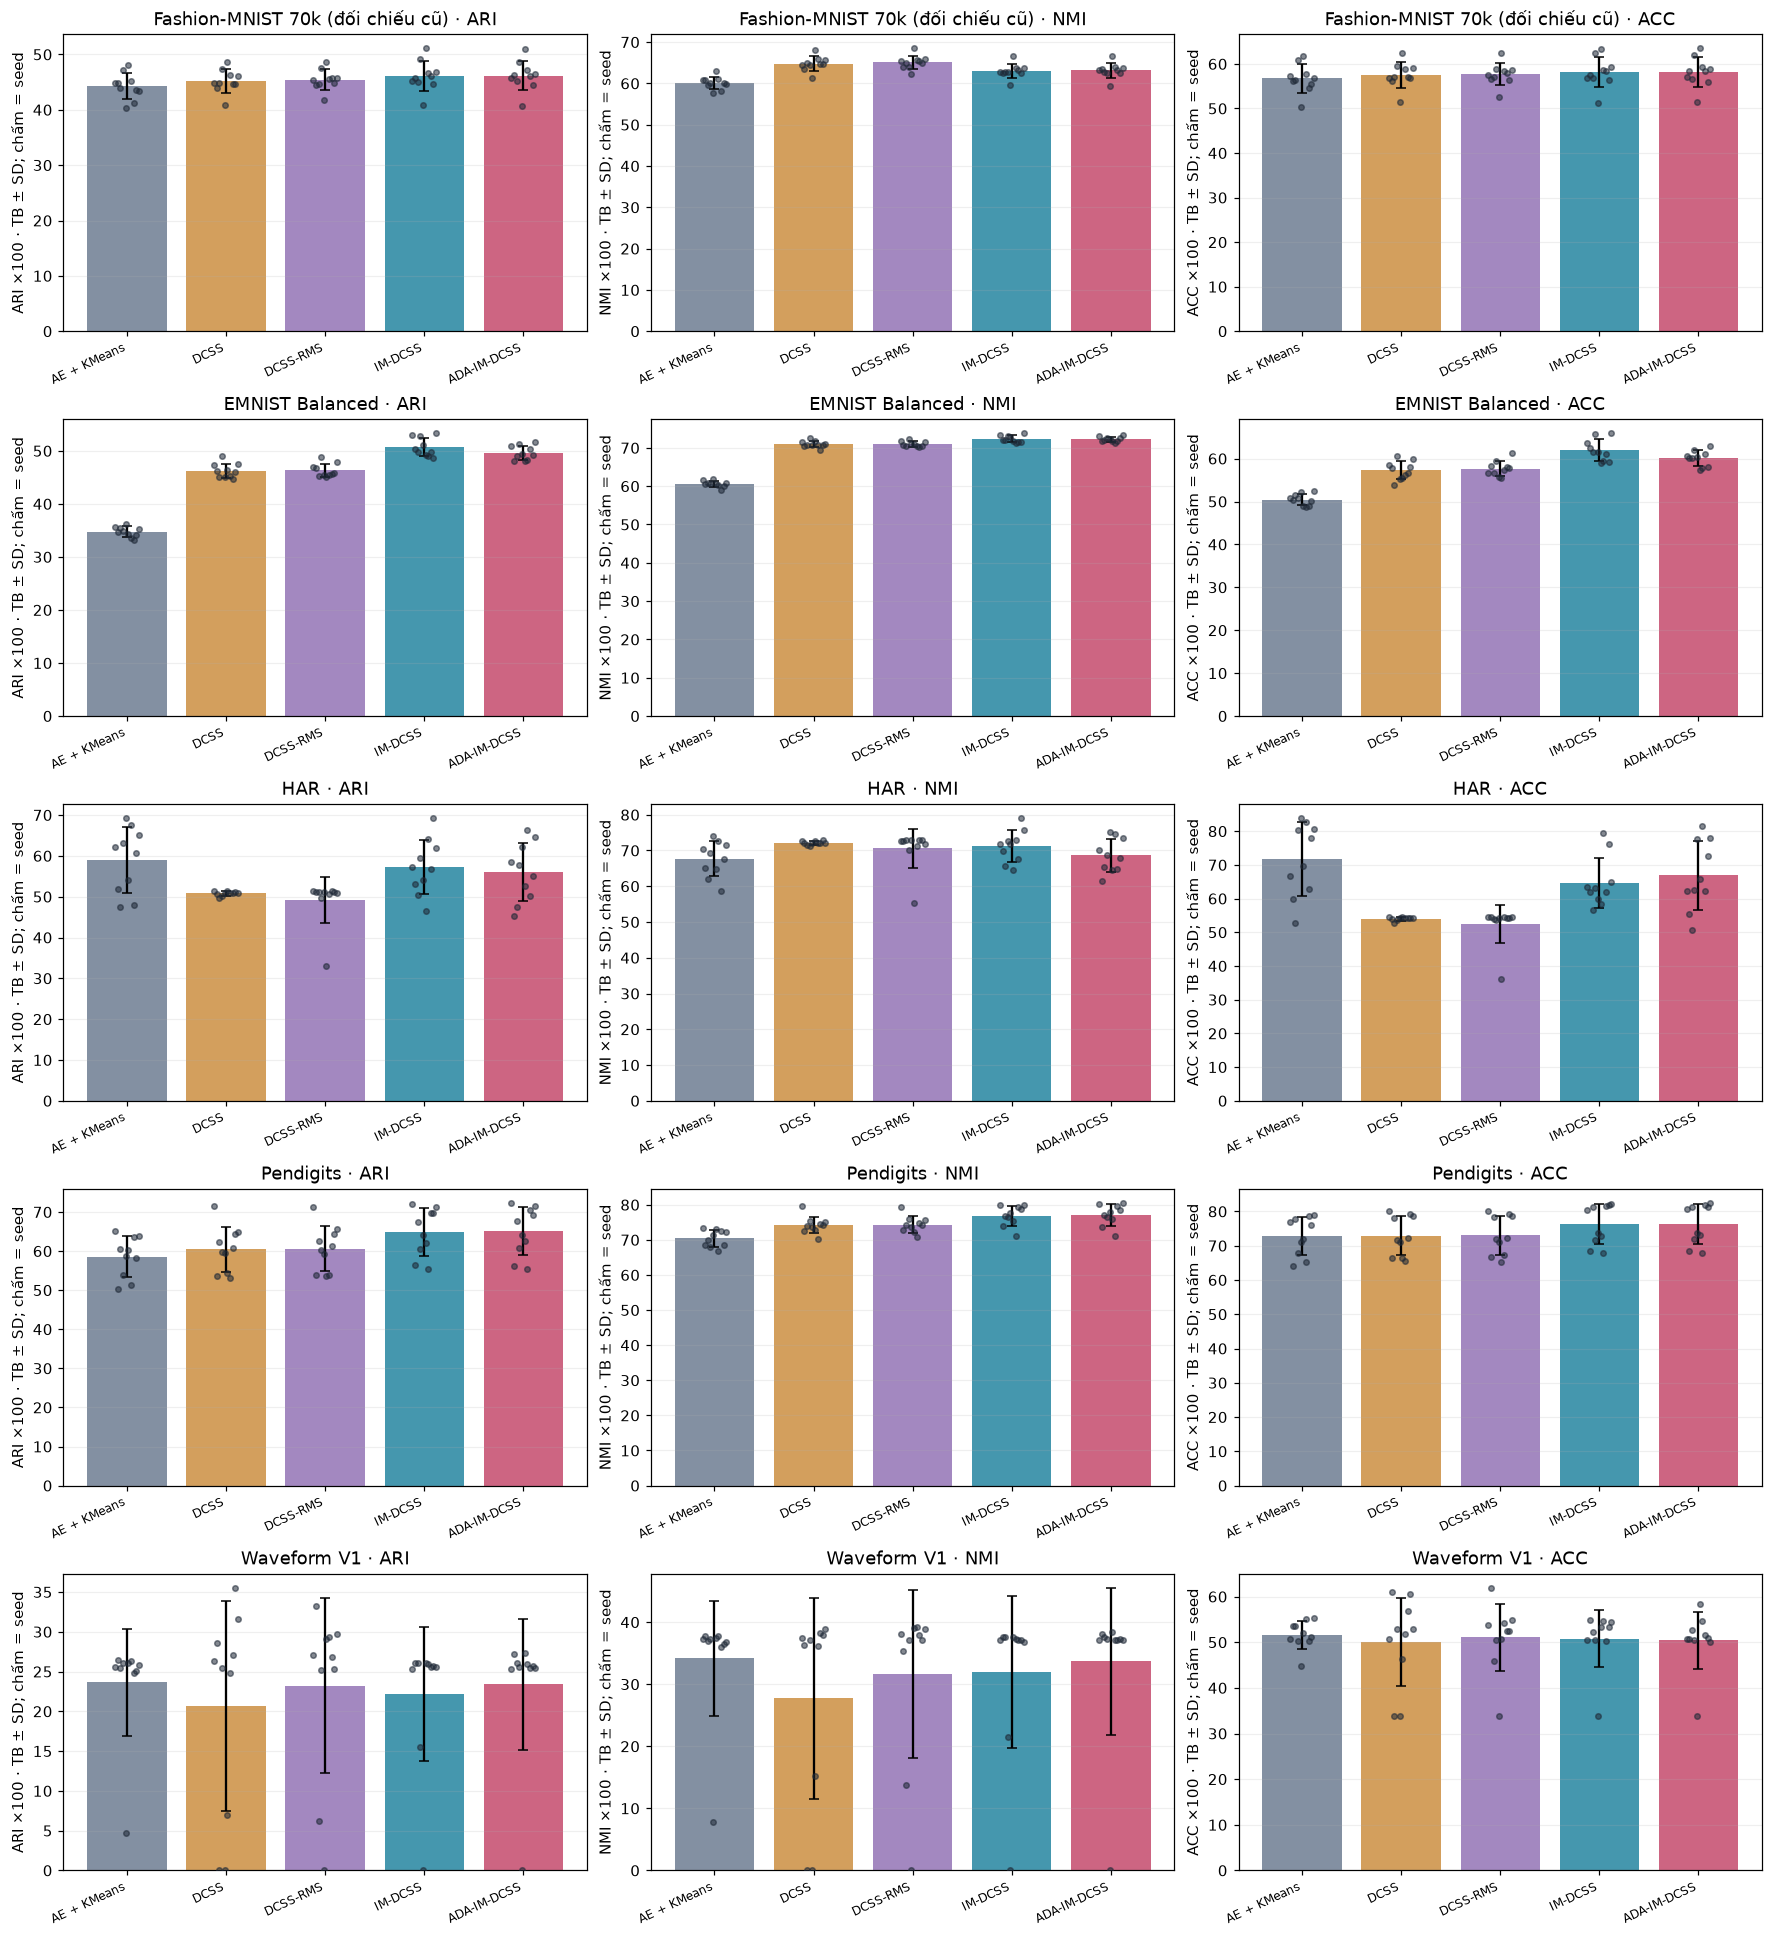

In [6]:
for dataset in (analysis.FASHION,"emnist","har","pendigits","waveform"):
    if dataset in payload["datasets"]:
        display(Markdown("### "+analysis.DATA_NAMES[dataset]))
        display(analysis.display_summary(summary,dataset,("ARI","NMI","ACC")))
analysis.plot_label_scores(frame,summary,OUTPUT_DIR)

## 5. Nemotron: chỉ số nội tại trên cùng không gian đặc trưng

Silhouette và CH cao hơn, DB thấp hơn là dấu hiệu thuận lợi **trong cùng biểu
diễn và cùng mẫu đánh giá**. Cần xem tiếp số cụm hoạt động: gom thành 1–3 cụm
có thể cho chỉ số nội tại tưởng như tốt dù K đã đặt là 20.
Không thay giá trị không xác định bằng 0. Cột “hợp lệ/đã xong” cho biết trung bình
được tính từ bao nhiêu seed. Văn bản dùng encoder cố định và giới hạn 128 token.

,Phương pháp,Silhouette chung,silhouette_common (hợp lệ/đã xong),Davies–Bouldin,DB_common (hợp lệ/đã xong),Calinski–Harabasz,CH_common (hợp lệ/đã xong)
0,AE + KMeans,0.026 ± 0.001,10/10,3.673 ± 0.026,10/10,43.324 ± 0.041,10/10
1,DCSS,0.089 ± 0.015,9/10,2.976 ± 0.189,9/10,167.980 ± 76.023,9/10
2,DCSS-RMS,0.105 ± 0.001,10/10,2.805 ± 0.157,10/10,218.183 ± 74.581,10/10
3,IM-DCSS,-0.000 ± 0.008,10/10,4.715 ± 0.529,10/10,37.249 ± 2.222,10/10
4,ADA-IM-DCSS,0.001 ± 0.020,10/10,4.250 ± 0.631,10/10,52.876 ± 8.925,10/10


,Số văn bản,Số chiều,Số hồ sơ bị cắt token,Tỷ lệ bị cắt,Tổng token gốc
0,100000,384,17260,0.1726,11120124


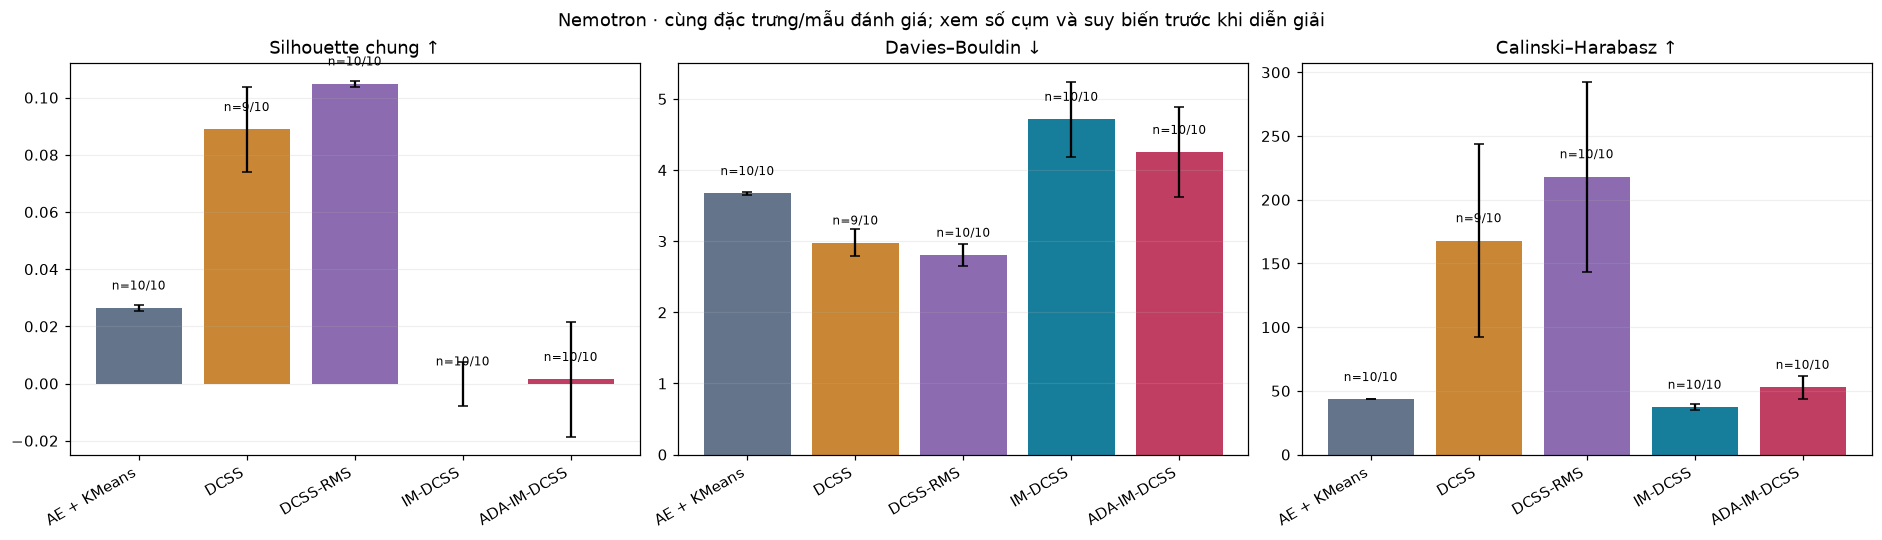

In [7]:
display(analysis.display_summary(summary,"personas",analysis.METRICS[3:]))
embedding = payload["datasets"]["personas"].get("embedding") or {}
if embedding:
    display(pd.DataFrame([{"Số văn bản":embedding.get("n"),"Số chiều":embedding.get("dimension"),
        "Số hồ sơ bị cắt token":embedding.get("truncated_rows"),
        "Tỷ lệ bị cắt":embedding.get("truncated_rows",0)/embedding["n"],
        "Tổng token gốc":embedding.get("original_token_count")}]))
analysis.plot_personas(frame,summary,OUTPUT_DIR)

## 6. ADA-IM có thêm lợi ích so với IM hay không?

So sánh chính: **ADA-IM − IM**, ghép đúng seed. Dùng ARI ở bốn bộ có nhãn và
silhouette chung ở Nemotron. Hiệu chỉnh Holm cho **5 phép thử**, không gồm
Fashion-MNIST cũ. CI 95% theo t trong hình là CI từng bộ chưa hiệu chỉnh; p Holm
mới dùng cho họ kiểm định đã chốt.

Chênh lệch dương có lợi cho ADA theo hai thước đo này. p lớn hơn 0,05 không chứng
minh tương đương hoặc không có tác dụng. Kết quả còn phụ thuộc biểu diễn, suy
biến và môi trường. Các so sánh với DCSS, DCSS-RMS và AE + KMeans được xuất riêng.

,dataset,metric,n,complete,mean_delta,ci95_low,ci95_high,wins,losses,ties,p_raw,p_holm_family5
18,EMNIST Balanced,ARI,10,True,-0.010786,-0.017833,-0.003739,2,8,0,0.011719,0.058594
42,HAR,ARI,10,True,-0.012594,-0.061318,0.036131,5,5,0,0.582031,1.000000
66,Pendigits,ARI,10,True,0.001815,-0.000516,0.004147,7,3,0,0.121094,0.484375
90,Waveform V1,ARI,10,True,0.011988,-0.010551,0.034527,3,6,1,0.250000,0.750000
105,Nemotron 100k,silhouette_common,10,True,0.001551,-0.017502,0.020605,4,6,0,0.857422,1.000000


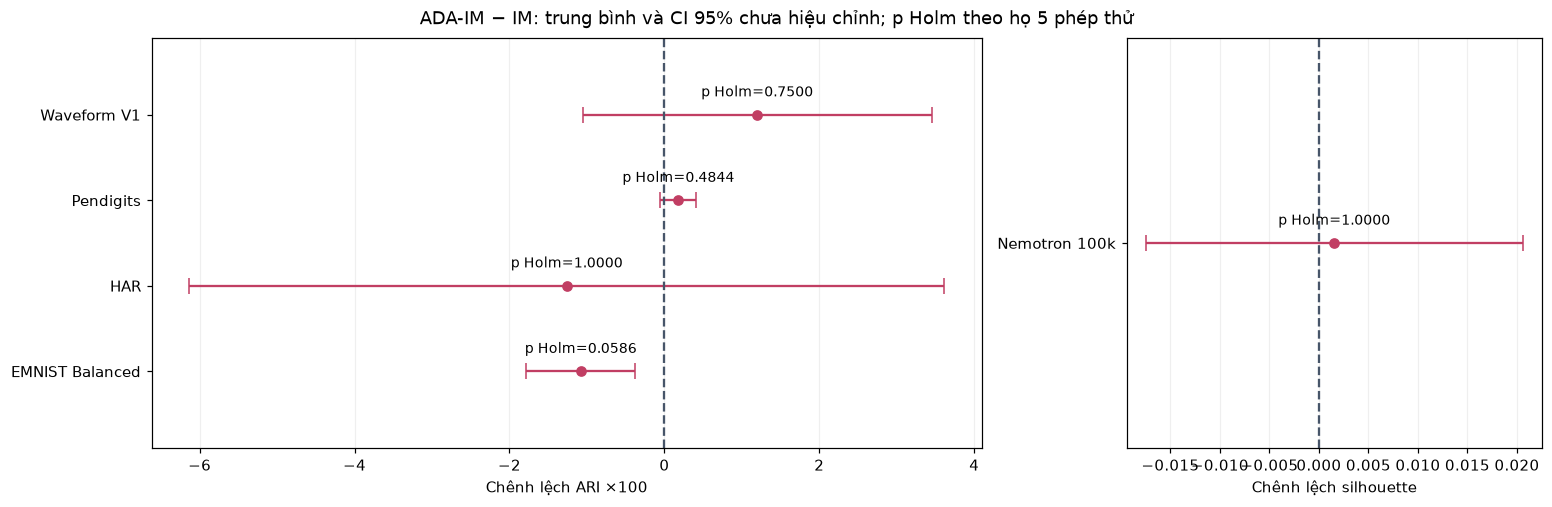

**Chưa xác nhận lợi ích bổ sung rõ ràng của ADA so với IM trên năm bộ này sau hiệu chỉnh Holm ở mức 0,05.**

In [8]:
primary_display = primary[["dataset","metric","n","complete","mean_delta","ci95_low","ci95_high",
    "wins","losses","ties","p_raw","p_holm_family5"]].copy()
primary_display["dataset"] = primary_display.dataset.map(analysis.DATA_NAMES)
display(primary_display)
analysis.plot_primary(primary,OUTPUT_DIR)
if primary.complete.all() and (primary.p_holm_family5.notna()).all():
    significant = primary[primary.p_holm_family5<.05]
    if significant.empty:
        display(Markdown("**Chưa xác nhận lợi ích bổ sung rõ ràng của ADA so với IM trên năm bộ này sau hiệu chỉnh Holm ở mức 0,05.**"))
    else:
        display(Markdown("**Có chênh lệch đạt ngưỡng kiểm định; cần đọc chiều tác động, CI và hạn chế trước khi kết luận.**"))
        display(significant)
else:
    display(Markdown("**Chưa đủ cặp seed hợp lệ để kết luận cả chiến dịch.**"))

## 7. Suy biến, số cụm hoạt động và các giá trị thiếu

Giữ nguyên mọi lượt chạy, kể cả kết quả bất lợi. Cờ suy biến dùng ngưỡng của bộ
thực thi; không bị gắn cờ vẫn có thể có ít cụm hơn K. AE + KMeans không có cờ
chẩn đoán của đầu phân cụm DCSS, nên ô cờ được để trống thay vì gán “không suy biến”.
Các lượt một cụm vẫn có ARI/NMI/ACC khi có nhãn, nhưng chỉ số nội tại có thể không
xác định. Không diễn giải trung bình chỉ số nội tại như đủ 10 giá trị khi thiếu.

,dataset,method,completed,K,flagged_collapsed,single_cluster_runs,active_min,active_mean,active_max,largest_cluster_max,undefined_internal
0,EMNIST Balanced,AE + KMeans,10,47,NaN,0,47.0,47.0,47.0,0.046026,0
1,EMNIST Balanced,DCSS,10,47,0.0,0,44.0,45.4,47.0,0.072264,0
2,EMNIST Balanced,DCSS-RMS,10,47,0.0,0,44.0,45.1,46.0,0.064088,0
3,EMNIST Balanced,IM-DCSS,10,47,0.0,0,47.0,47.0,47.0,0.039347,0
4,EMNIST Balanced,ADA-IM-DCSS,10,47,0.0,0,43.0,45.1,47.0,0.065220,0
5,HAR,AE + KMeans,10,6,NaN,0,6.0,6.0,6.0,0.347412,0
6,HAR,DCSS,10,6,0.0,0,3.0,3.5,4.0,0.454219,0
7,HAR,DCSS-RMS,10,6,0.0,0,3.0,3.6,5.0,0.546072,0
8,HAR,IM-DCSS,10,6,0.0,0,4.0,5.0,6.0,0.390523,0
9,HAR,ADA-IM-DCSS,10,6,0.0,0,5.0,5.9,6.0,0.362268,0


Tổng lượt tinh chỉnh bị gắn cờ suy biến: 26


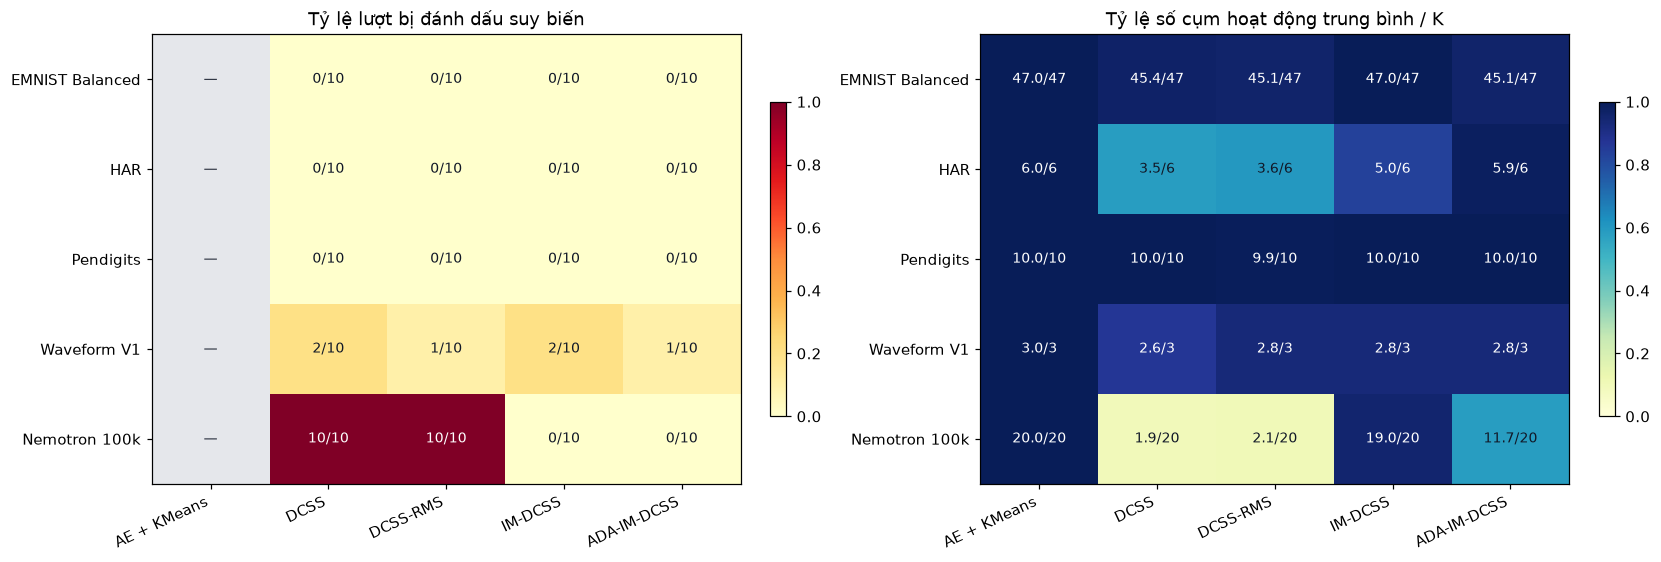

,Bộ dữ liệu,Seed,Phương pháp,hard_active_clusters,common_metric_status
162,waveform,2,dcss_paper,1.0,undefined_singleton_or_degenerate_partition
170,waveform,4,ada_im,1.0,undefined_singleton_or_degenerate_partition
172,waveform,4,dcss_paper,1.0,undefined_singleton_or_degenerate_partition
173,waveform,4,dcss_rms,1.0,undefined_singleton_or_degenerate_partition
174,waveform,4,im_rms,1.0,undefined_singleton_or_degenerate_partition
217,personas,3,dcss_paper,1.0,undefined_singleton_or_degenerate_partition


In [9]:
health_display = health.copy()
health_display["dataset"] = health_display.dataset.map(analysis.DATA_NAMES)
health_display["method"] = health_display.method.map(analysis.METHOD_NAMES)
display(health_display)
print("Tổng lượt tinh chỉnh bị gắn cờ suy biến:",int(health.flagged_collapsed.sum()))
analysis.plot_health(health,OUTPUT_DIR)
invalid = frame[(frame.dataset!=analysis.FASHION)&frame.silhouette_common.isna()]
display(invalid[["dataset","seed","method","hard_active_clusters","common_metric_status"]]
        .rename(columns={"dataset":"Bộ dữ liệu","seed":"Seed","method":"Phương pháp"}))

## 8. Độ ổn định giữa các seed

ARI ở đây so sánh **hai phân hoạch**, không so với nhãn đúng. 10 seed tạo 45 cặp
phụ thuộc nhau, vì vậy không coi chúng là 45 quan sát độc lập để kiểm định.
Độ ổn định cao không bảo đảm chất lượng cao, đặc biệt khi các lượt cùng suy biến.
Các giá trị này được đọc từ partition_stability.json đã lưu, không tính lại từ
250 tệp dự đoán trong notebook thống kê.

,dataset,method,seeds,pairs,partition_ARI_mean,pairwise_sd_descriptive
0,emnist,ae_kmeans,10,45,0.576183,0.030687
1,emnist,dcss_paper,10,45,0.643844,0.043587
2,emnist,dcss_rms,10,45,0.650013,0.035311
3,emnist,im_rms,10,45,0.643820,0.030567
4,emnist,ada_im,10,45,0.641752,0.038286
5,har,ae_kmeans,10,45,0.619848,0.094915
6,har,dcss_paper,10,45,0.986217,0.006975
7,har,dcss_rms,10,45,0.933869,0.107212
8,har,im_rms,10,45,0.684907,0.104339
9,har,ada_im,10,45,0.578529,0.073117


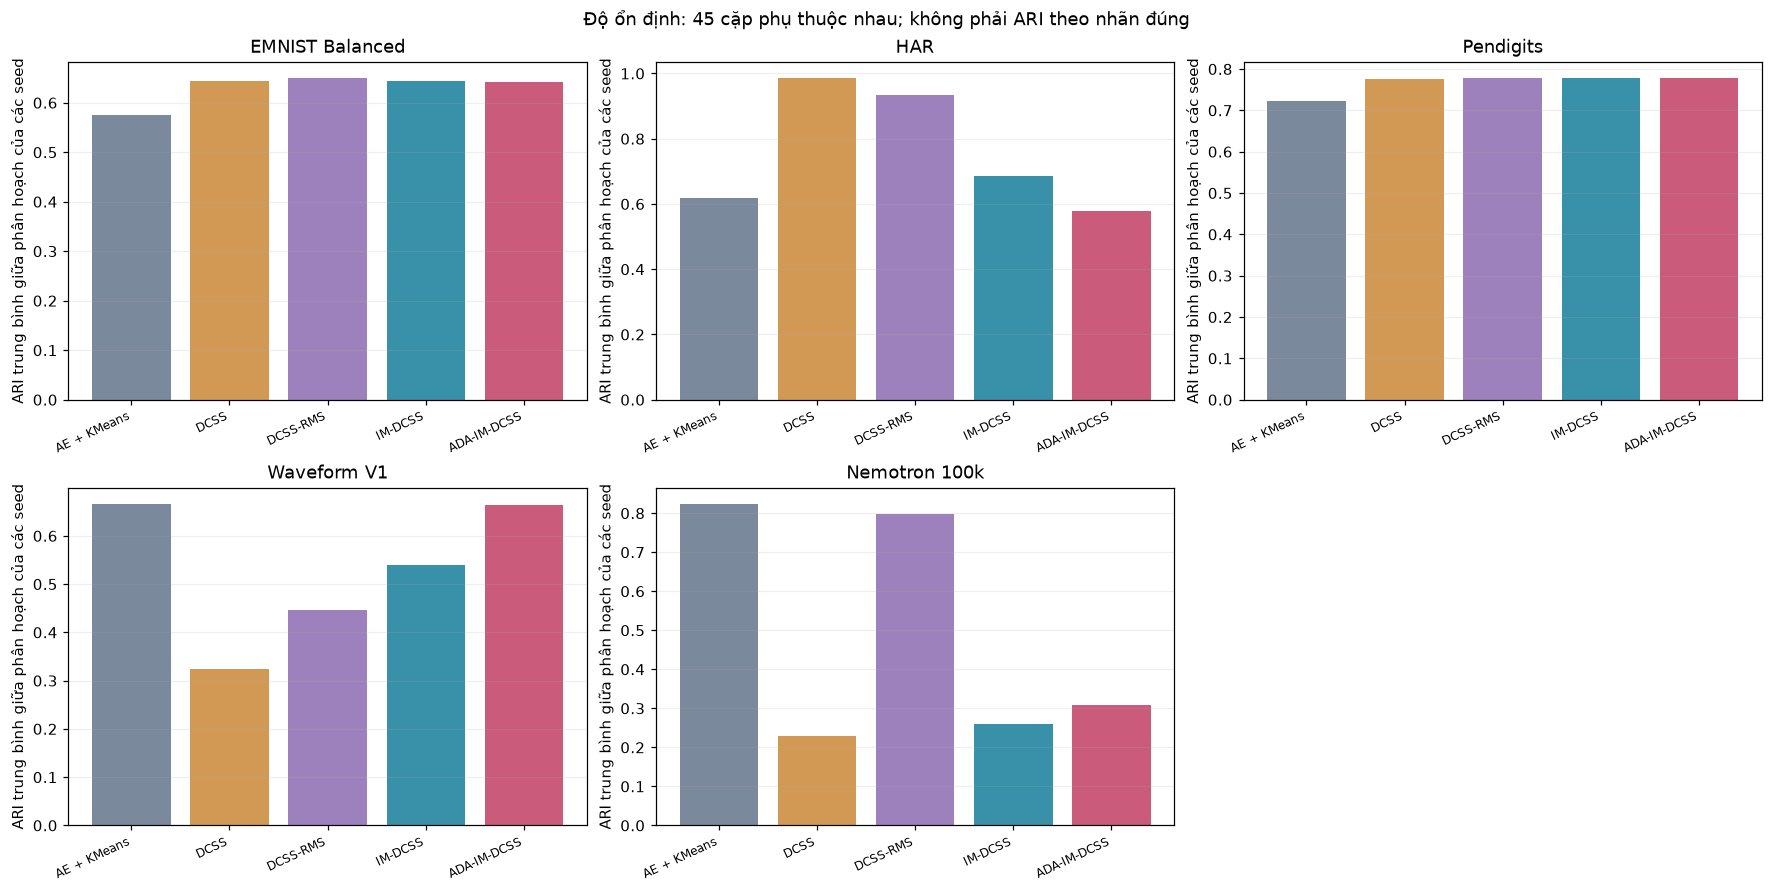

In [10]:
stability = pd.DataFrame(payload["stability"])
display(stability[["dataset","method","seeds","pairs","partition_ARI_mean","pairwise_sd_descriptive"]])
analysis.plot_stability(payload,OUTPUT_DIR)

## 9. Quá trình học và thời gian

Đường là trung bình, vùng mờ là SD qua các seed. Biểu đồ dùng MSE tái tạo và
silhouette mềm; không so tổng loss giữa các phương pháp có hệ số khác nhau để
khẳng định phương pháp nào tốt hơn. Thời gian dưới đây là thời gian giai đoạn
đã ghi, không bao gồm đầy đủ tải dữ liệu/mã hóa văn bản/KMeans và không phải
tổng thời gian treo phiên. Không cộng lặp phần tiền huấn luyện dùng chung.

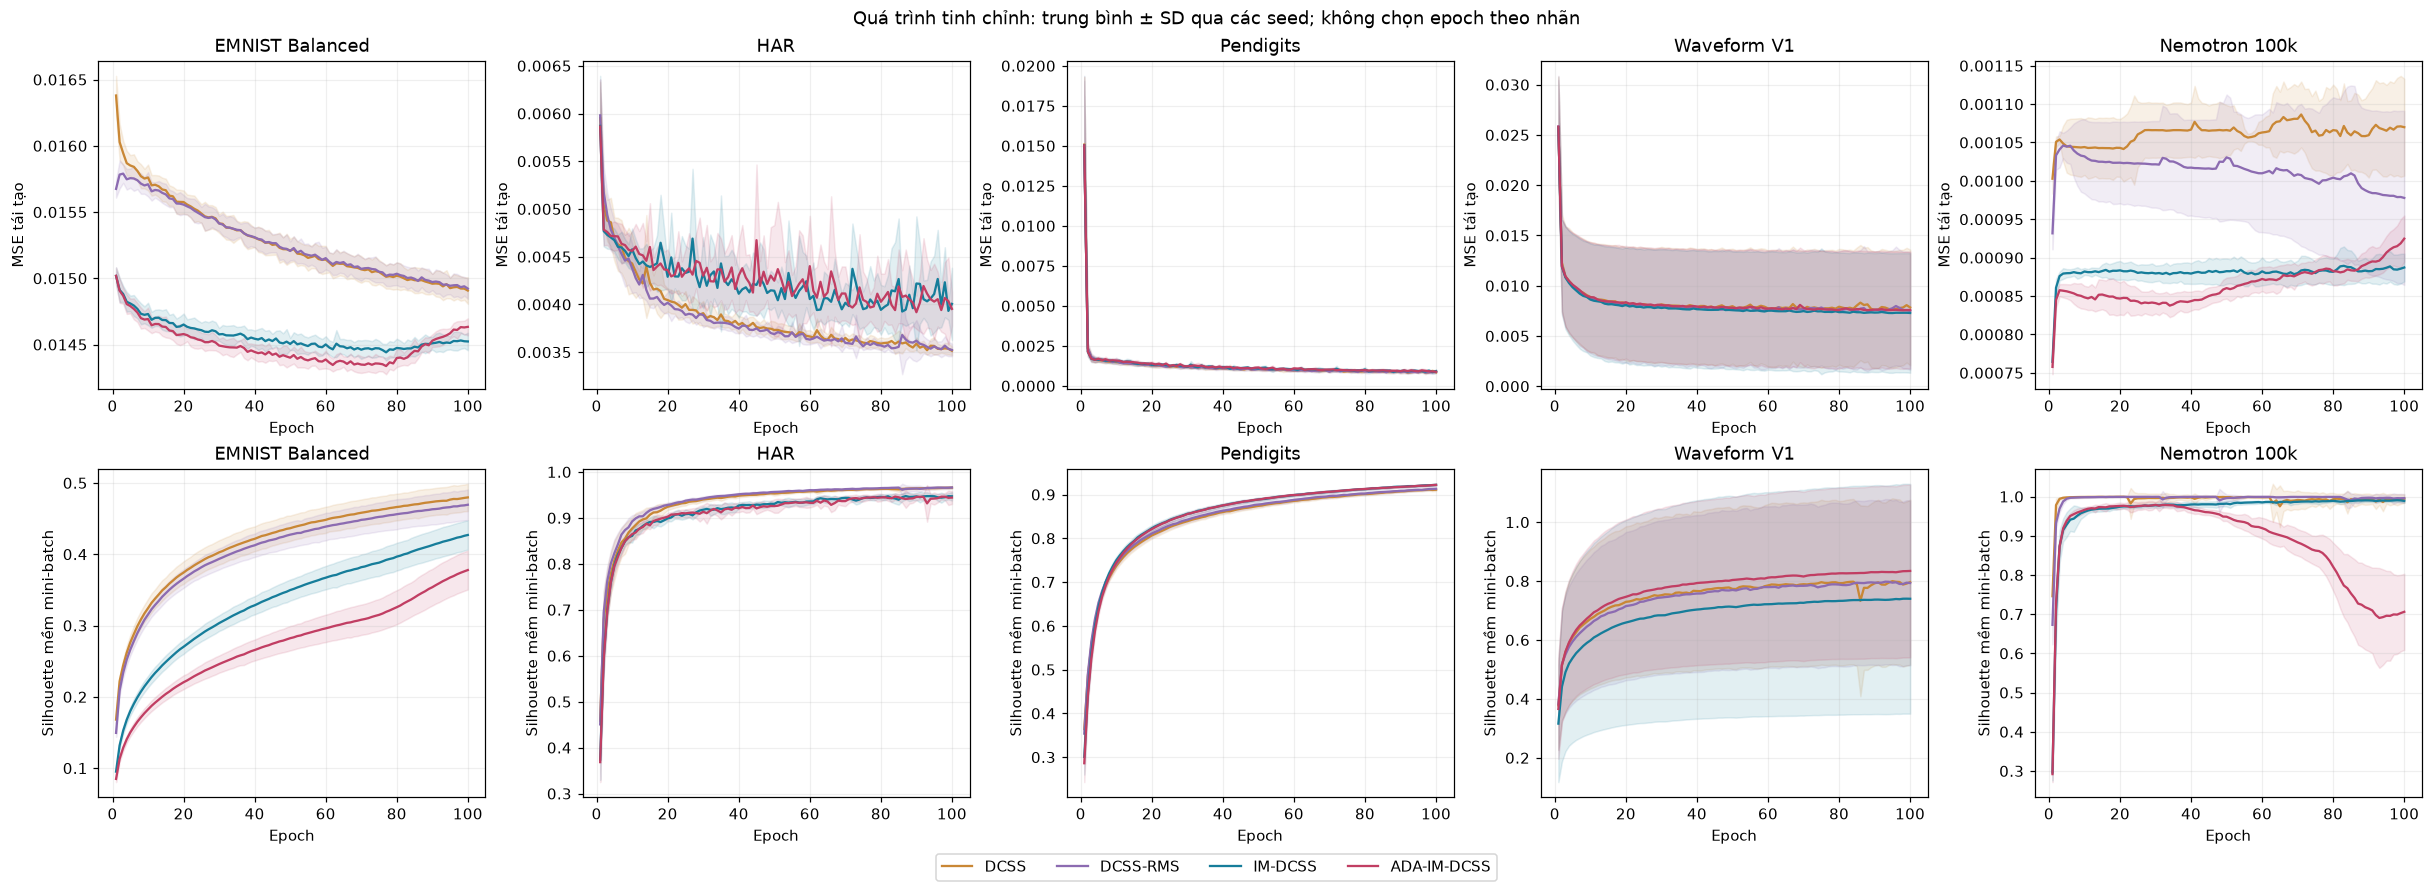

,dataset,method,seeds,finetune_minutes_mean,finetune_minutes_sd,peak_gpu_gb,mixed_environment_runs
0,emnist,ada_im,10,13.962590,0.224977,0.118988,0
1,emnist,ae_kmeans,10,0.000000,0.000000,NaN,0
2,emnist,dcss_paper,10,12.719174,0.191138,0.119035,0
3,emnist,dcss_rms,10,12.851536,0.222368,0.119035,0
4,emnist,im_rms,10,12.840279,0.200269,0.119035,0
5,har,ada_im,10,0.621183,0.002731,0.139191,1
6,har,ae_kmeans,10,0.000000,0.000000,NaN,1
7,har,dcss_paper,10,0.598126,0.001909,0.139193,1
8,har,dcss_rms,10,0.610325,0.003191,0.139193,1
9,har,im_rms,10,0.608981,0.003528,0.139193,1


In [11]:
analysis.plot_histories(payload,OUTPUT_DIR)
new_runs = frame[frame.dataset!=analysis.FASHION].copy()
new_runs["finetune_minutes"] = new_runs.finetune_seconds/60
timing = new_runs.groupby(["dataset","method"]).agg(
    seeds=("seed","count"),finetune_minutes_mean=("finetune_minutes","mean"),
    finetune_minutes_sd=("finetune_minutes","std"),peak_gpu_gb=("peak_gpu_gb","max"),
    mixed_environment_runs=("mixed_environment","sum")).reset_index()
display(timing)
timing.to_csv(OUTPUT_DIR/"timing.csv",index=False,encoding="utf-8-sig")

## 10. Dò từng seed và phân bố cụm
Đổi ba biến ở ô dưới rồi chạy lại riêng ô để xem một kết quả. Cụm số 0 của hai mô hình không mặc nhiên cùng ý nghĩa.

,dataset,method,seed,ARI,NMI,ACC,silhouette_common,DB_common,CH_common,hard_active_clusters,hard_largest_cluster_fraction
200,personas,ada_im,0,NaN,NaN,NaN,-0.024053,3.702591,43.927246,12.0,0.31769


,Cụm,Số mẫu,Tỷ lệ
0,0,0,0.00000
1,1,0,0.00000
2,2,0,0.00000
3,3,29791,0.29791
4,4,5761,0.05761
5,5,1975,0.01975
6,6,2772,0.02772
7,7,0,0.00000
8,8,0,0.00000
9,9,10303,0.10303


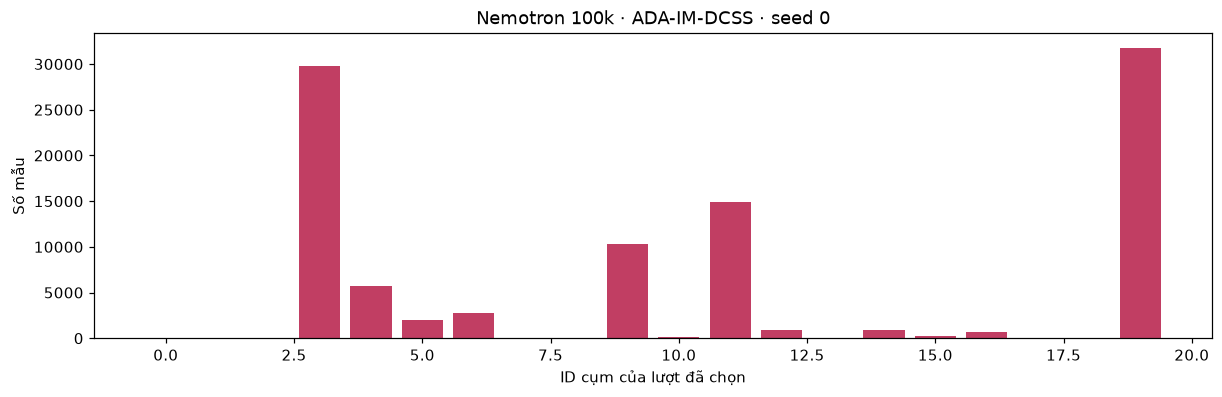

,dataset,method,seed,ARI,NMI,ACC,silhouette_common,DB_common,CH_common,hard_active_clusters,collapsed
200,personas,ada_im,0,NaN,NaN,NaN,-0.024053,3.702591,43.927246,12.0,False
205,personas,ada_im,1,NaN,NaN,NaN,-0.001147,5.112165,50.011528,13.0,False
210,personas,ada_im,2,NaN,NaN,NaN,0.017089,4.197232,60.750225,11.0,False
215,personas,ada_im,3,NaN,NaN,NaN,0.022615,4.584981,68.734108,9.0,False
220,personas,ada_im,4,NaN,NaN,NaN,0.038251,3.375699,60.387257,10.0,False
225,personas,ada_im,5,NaN,NaN,NaN,0.002950,3.760906,56.505756,10.0,False
230,personas,ada_im,6,NaN,NaN,NaN,-0.007540,4.294032,43.343136,12.0,False
235,personas,ada_im,7,NaN,NaN,NaN,-0.023751,3.862186,55.786018,10.0,False
240,personas,ada_im,8,NaN,NaN,NaN,-0.012942,4.236204,42.307316,16.0,False
245,personas,ada_im,9,NaN,NaN,NaN,0.003249,5.378524,47.006496,14.0,False


In [12]:
VIEW_DATASET = "personas"
VIEW_METHOD = "ada_im"
VIEW_SEED = 0
selected = frame[(frame.dataset==VIEW_DATASET)&(frame.method==VIEW_METHOD)&(frame.seed==VIEW_SEED)]
display(selected[["dataset","method","seed",*analysis.METRICS,"hard_active_clusters","hard_largest_cluster_fraction"]])
cluster_table = analysis.cluster_detail(frame,VIEW_DATASET,VIEW_METHOD,VIEW_SEED)
display(cluster_table)
fig,ax = plt.subplots(figsize=(11,3.5),layout="constrained")
ax.bar(cluster_table["Cụm"],cluster_table["Số mẫu"],color="#c13e63")
ax.set(xlabel="ID cụm của lượt đã chọn",ylabel="Số mẫu",
       title=analysis.DATA_NAMES[VIEW_DATASET]+" · "+analysis.METHOD_NAMES[VIEW_METHOD]+f" · seed {VIEW_SEED}")
analysis.save_show(fig,OUTPUT_DIR/"07_selected_cluster_distribution.png")
display(frame[frame.dataset==VIEW_DATASET][["dataset","method","seed",*analysis.METRICS,
    "hard_active_clusters","collapsed"]].sort_values(["method","seed"]))

## 11. Xuất toàn bộ bảng và biểu đồ

Thư mục xuất chứa CSV/JSON, ảnh PNG, báo cáo HTML có ảnh nhúng và gói ZIP.
HTML có thể mở độc lập bằng trình duyệt. Notebook đã có sẵn kết quả hiển thị,
nhưng CSV/JSON luôn giữ đơn vị gốc để dùng phân tích tiếp. Không ghi vào thư mục
checkpoint hay dữ liệu gốc.

In [13]:
tables = analysis.export_tables(OUTPUT_DIR,payload,frame,progress,summary,health,all_pairs,primary)
html_path,zip_path = analysis.export_html_zip(OUTPUT_DIR,tables,primary)
print("Đã xuất:",html_path)
print("Gói đầy đủ:",zip_path)
print("Bảng chính:",OUTPUT_DIR/"summary.csv")
if "google.colab" not in sys.modules:
    display(FileLink(str(html_path)))
    display(FileLink(str(zip_path)))
else:
    print("Trên Colab: mở thanh Files và tải ZIP, hoặc đặt DOWNLOAD_ZIP=True ở ô cuối.")

Đã xuất: F:\ThacSi\Data Mining\final\DCSS_MultiDataset_Statistics\ThongKe_DCSS_MultiDataset.html
Gói đầy đủ: F:\ThacSi\Data Mining\final\DCSS_MultiDataset_Statistics\ThongKe_DCSS_MultiDataset.zip
Bảng chính: F:\ThacSi\Data Mining\final\DCSS_MultiDataset_Statistics\summary.csv


F:\ThacSi\Data Mining\final\DCSS_MultiDataset_Statistics\ThongKe_DCSS_MultiDataset.html

F:\ThacSi\Data Mining\final\DCSS_MultiDataset_Statistics\ThongKe_DCSS_MultiDataset.zip

In [14]:
DOWNLOAD_ZIP = False
if DOWNLOAD_ZIP:
    if "google.colab" in sys.modules:
        from google.colab import files
        files.download(str(zip_path))
    else:
        display(FileLink(str(zip_path)))